# Does a readout beat random features?

| | |
| --- | --- |
| **Question** | Does a linear readout from informative features score above the distribution of scores obtained from random features? |
| **Requires** | CPU only; NumPy, scikit-learn, matplotlib. No downloads. Under 10 seconds. |
| **Lessons used** | [6. Behavior](../lessons/06_behavior.ipynb), [2. Your first benchmark](../lessons/02_your_first_benchmark.ipynb) |

## Background

A behavioral score is only interpretable relative to what a system without the relevant
information would score. A trained readout can exploit chance structure in any features,
so the reference is not simply the chance level of the task. The reference used here is
a null distribution: the scores of the same readout fitted to many sets of random
features.

All data in this notebook are synthetic. The two-class design stands in for a lexical
decision task such as ROAR (real word versus pseudoword).

## Hypothesis

Features in which one dimension carries the class label will produce a held-out balanced
accuracy above the 95th percentile of the random-feature null distribution.

## Method

The task has 60 stimuli in two balanced classes. The first 40 stimuli train the readout
and the last 20 are held out for testing. Balanced accuracy averages the accuracy on each
class, so 0.5 is chance and 1.0 is perfect.

The next cell defines the labels and the split.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score

n_stimuli, n_features = 60, 64
labels = np.array([0, 1] * (n_stimuli // 2))
train, test = np.arange(0, 40), np.arange(40, 60)
print(f'{n_stimuli} stimuli, {len(train)} train, {len(test)} held out')

60 stimuli, 40 train, 20 held out


The readout is a logistic regression fitted on the training stimuli and scored on
the held-out stimuli.

In [2]:
def readout_accuracy(features):
    clf = LogisticRegression(max_iter=500).fit(features[train], labels[train])
    return balanced_accuracy_score(labels[test], clf.predict(features[test]))

The null distribution comes from 200 independent sets of Gaussian random features.
None of them carries label information.

In [3]:
null = np.array([readout_accuracy(np.random.RandomState(seed).randn(n_stimuli, n_features))
                 for seed in range(200)])
null_lo, null_median, null_hi = np.percentile(null, [5, 50, 95])

The test features are random except for the first dimension, which is shifted up for
class 1 and down for class 0.

In [4]:
rng = np.random.RandomState(0)
informative = rng.randn(n_stimuli, n_features)
informative[:, 0] += 3.0 * (labels - 0.5)
model_score = readout_accuracy(informative)

## Results

In [5]:
print(f'random-feature null: median {null_median:.2f}, 5-95% range [{null_lo:.2f}, {null_hi:.2f}]')
print(f'informative features: {model_score:.2f}')
print('above the 95th percentile of the null:', model_score > null_hi)

random-feature null: median 0.50, 5-95% range [0.30, 0.70]
informative features: 0.80
above the 95th percentile of the null: True


The random-feature scores have a median of 0.50, but the middle 90% spans 0.30 to
0.70 because only 20 stimuli are held out. The informative features score 0.80, above the
95th percentile of the null.

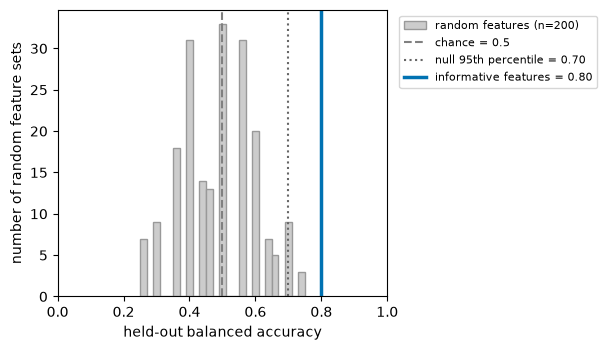

In [6]:
fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.hist(null, bins=25, color='0.8', edgecolor='0.6', label='random features (n=200)')
ax.axvline(0.5, ls='--', c='gray', label='chance = 0.5')
ax.axvline(null_hi, ls=':', c='0.4', label=f'null 95th percentile = {null_hi:.2f}')
ax.axvline(model_score, c='#0072B2', lw=2.5, label=f'informative features = {model_score:.2f}')
ax.set_xlim(0, 1)
ax.set_xlabel('held-out balanced accuracy')
ax.set_ylabel('number of random feature sets')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.02, 1))
fig.tight_layout()
plt.show()

The figure shows the full null distribution. Its width is the relevant scale for
judging a single score from a test set of this size.

## Conclusion and limits

On this synthetic task, a readout from features containing one informative dimension
scores above the random-feature null. A score inside the null band would not prove that
the features contain no information; it would only mean this test cannot distinguish them
from random features.

The data, the signal strength and the split are all synthetic choices. For a registered
benchmark, the null must use the same stimuli, the same split and the same readout as the
model being evaluated. Brain-Score provides the `random-vit-b-32` and `chance-baseline`
subjects for this purpose.

[Lessons](../lessons/) · [Documentation](../../docs/README.md)